In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Unemployment in India 2.csv to Unemployment in India 2.csv


In [3]:
df = pd.read_csv("Unemployment in India 2.csv")

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
df.shape

(754, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 754 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 41.4+ KB


In [6]:
df.columns

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [7]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [8]:
df.isnull().sum()

,0
Region,14
Date,14
Frequency,14
Estimated Unemployment Rate (%),14
Estimated Employed,14
Estimated Labour Participation Rate (%),14
Area,14


In [10]:
df.duplicated().sum()

np.int64(13)

In [11]:
df.isnull().sum().sum()

np.int64(98)

In [12]:
df[df.isnull().any(axis=1)]

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df[df.duplicated()]

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN
369,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
df_clean = df.dropna(how='all').copy()

df_clean.shape

(740, 7)

In [15]:
df_clean.isnull().sum()

,0
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0


In [16]:
df_clean.duplicated().sum()

np.int64(0)

In [17]:
df_clean.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [18]:
df_clean[' Estimated Unemployment Rate (%)'].mean()

np.float64(11.787945945945946)

In [19]:
state_unemployment = df_clean.groupby('Region')[' Estimated Unemployment Rate (%)'].mean()

state_unemployment.sort_values(ascending=False)

,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


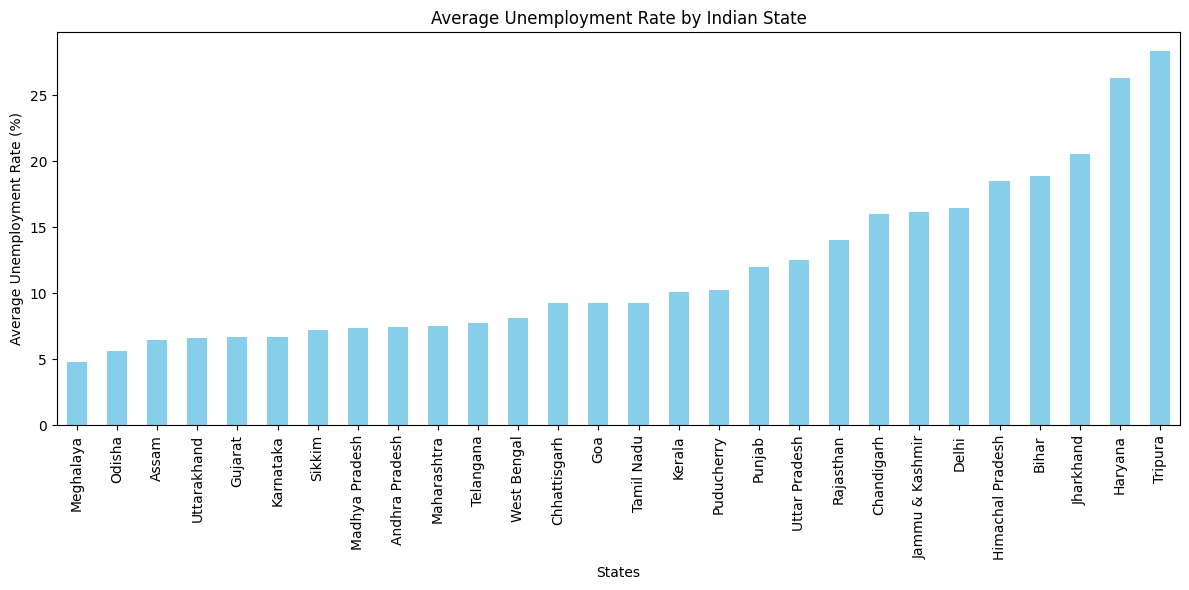

In [20]:
plt.figure(figsize=(12, 6))

state_unemployment.sort_values().plot(
    kind='bar',
    color='skyblue'
)

plt.title('Average Unemployment Rate by Indian State')
plt.xlabel('States')
plt.ylabel('Average Unemployment Rate (%)')

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [21]:
df_clean[' Date'] = pd.to_datetime(df_clean[' Date'])

df_clean[' Date'].min(), df_clean[' Date'].max()

/tmp/ipykernel_1177/1279085837.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_clean[' Date'] = pd.to_datetime(df_clean[' Date'])


(Timestamp('2019-05-31 00:00:00'), Timestamp('2020-06-30 00:00:00'))

In [22]:
monthly_unemployment = df_clean.groupby(
    df_clean[' Date'].dt.to_period('M')
)[' Estimated Unemployment Rate (%)'].mean()

monthly_unemployment

,Estimated Unemployment Rate (%)
Date,
2019-05,8.874259
2019-06,9.303333
2019-07,9.033889
2019-08,9.637925
2019-09,9.051731
2019-10,9.900909
2019-11,9.868364
2019-12,9.497358
2020-01,9.950755


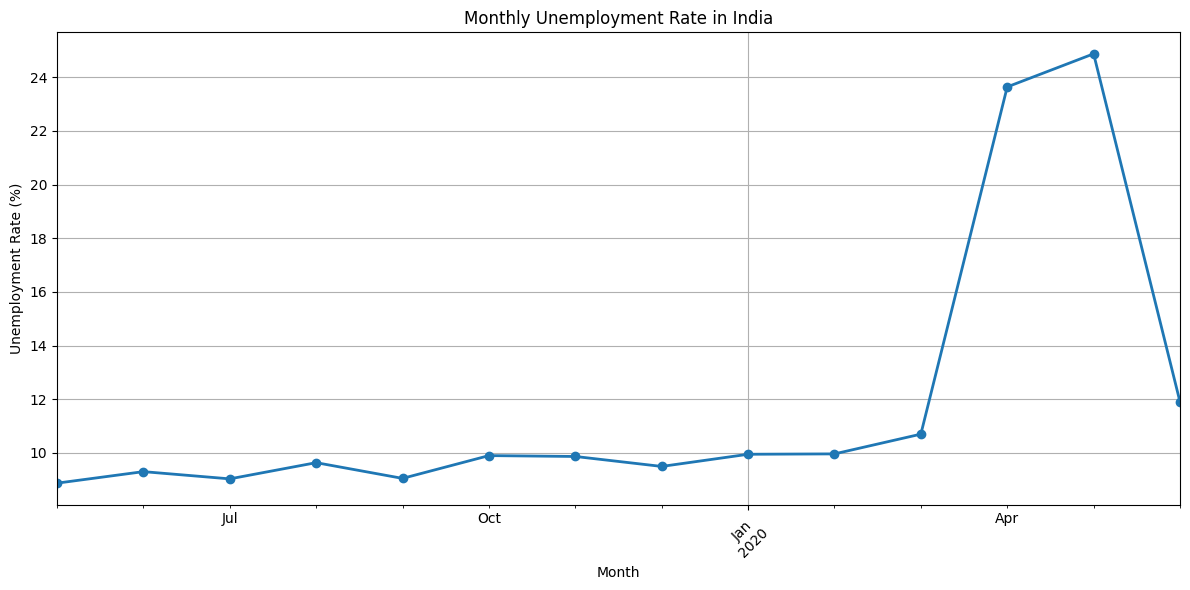

In [23]:
plt.figure(figsize=(12, 6))

monthly_unemployment.plot(
    marker='o',
    linewidth=2
)

plt.title('Monthly Unemployment Rate in India')
plt.xlabel('Month')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

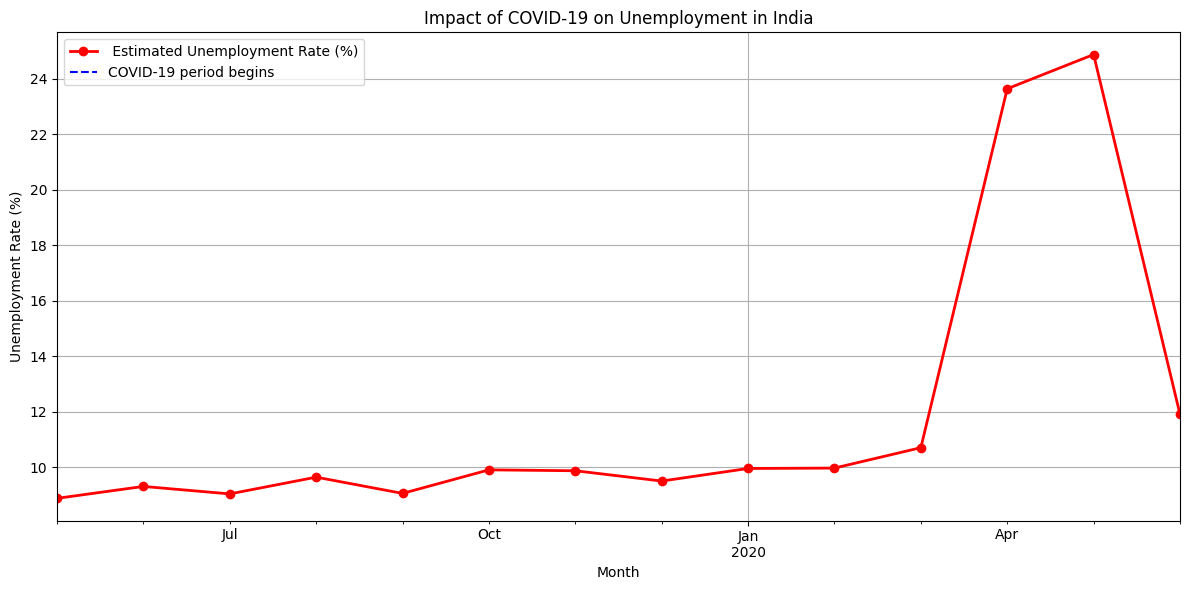

In [24]:
plt.figure(figsize=(12, 6))

monthly_unemployment.plot(
    marker='o',
    color='red',
    linewidth=2
)

plt.axvline(
    x=monthly_unemployment.index.get_loc('2020-03'),
    color='blue',
    linestyle='--',
    label='COVID-19 period begins'
)

plt.title('Impact of COVID-19 on Unemployment in India')
plt.xlabel('Month')
plt.ylabel('Unemployment Rate (%)')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
area_unemployment = df_clean.groupby('Area')[
    ' Estimated Unemployment Rate (%)'
].mean()

area_unemployment

,Estimated Unemployment Rate (%)
Area,
Rural,10.324791
Urban,13.166614


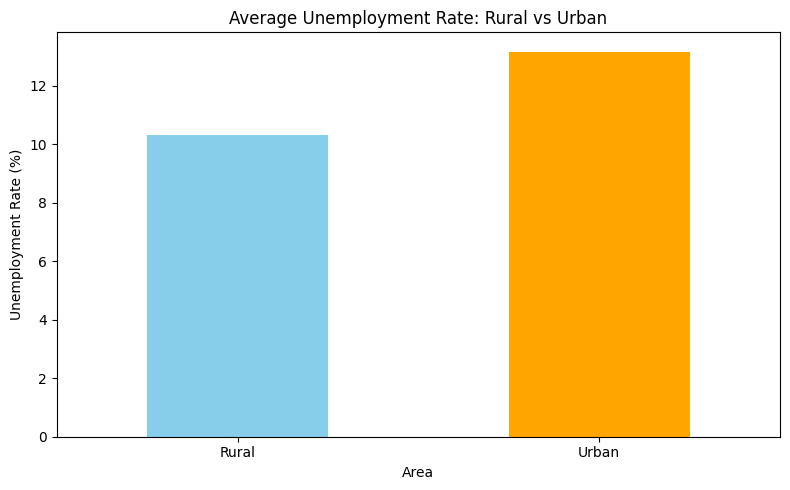

In [26]:
plt.figure(figsize=(8, 5))

area_unemployment.plot(
    kind='bar',
    color=['skyblue', 'orange']
)

plt.title('Average Unemployment Rate: Rural vs Urban')
plt.xlabel('Area')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

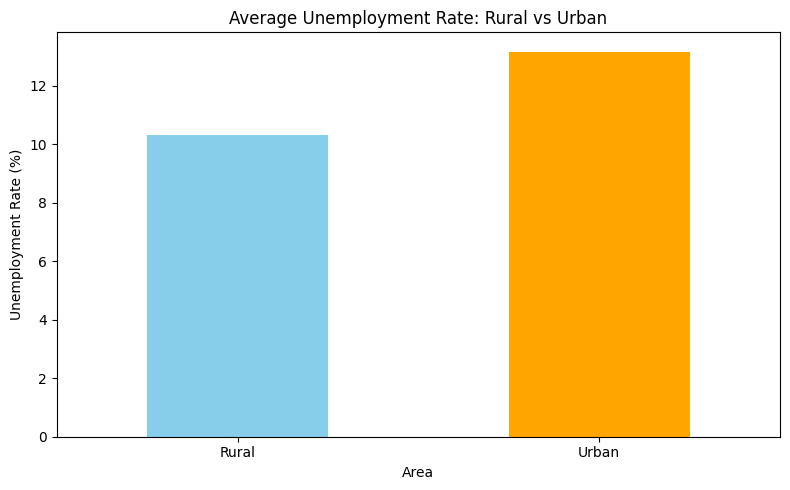

In [27]:
plt.figure(figsize=(8, 5))

area_unemployment.plot(
    kind='bar',
    color=['skyblue', 'orange']
)

plt.title('Average Unemployment Rate: Rural vs Urban')
plt.xlabel('Area')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
df_clean[' Estimated Labour Participation Rate (%)'].mean()

np.float64(42.630121621621626)

In [29]:
labour_participation = df_clean.groupby('Area')[
    ' Estimated Labour Participation Rate (%)'
].mean()

labour_participation

,Estimated Labour Participation Rate (%)
Area,
Rural,44.464819
Urban,40.901365


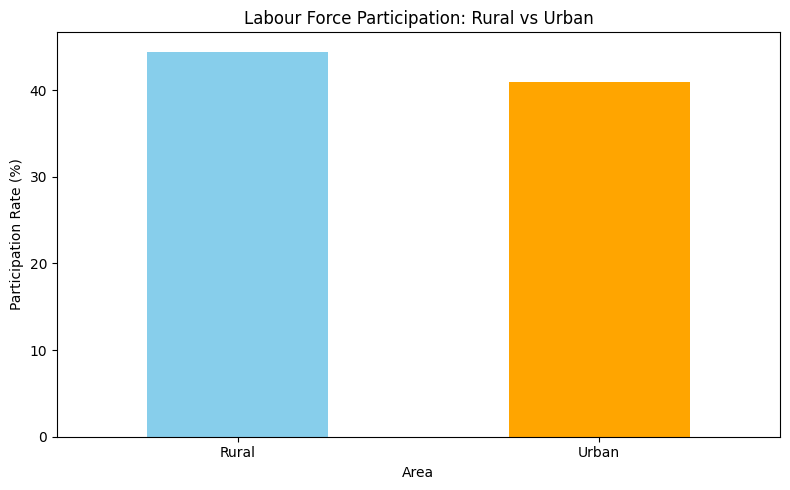

In [30]:
plt.figure(figsize=(8, 5))

labour_participation.plot(
    kind='bar',
    color=['skyblue', 'orange']
)

plt.title('Labour Force Participation: Rural vs Urban')
plt.xlabel('Area')
plt.ylabel('Participation Rate (%)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
labour_participation = df_clean.groupby('Area')[
    ' Estimated Labour Participation Rate (%)'
].mean()

labour_participation

,Estimated Labour Participation Rate (%)
Area,
Rural,44.464819
Urban,40.901365


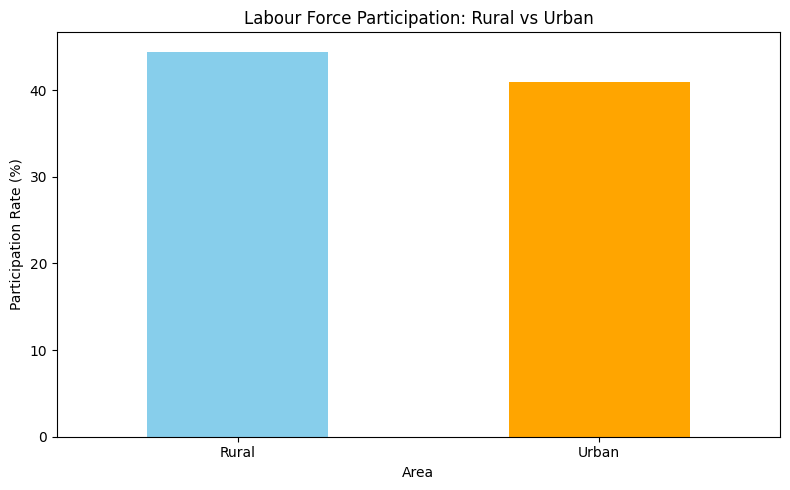

In [32]:
plt.figure(figsize=(8, 5))

labour_participation.plot(
    kind='bar',
    color=['skyblue', 'orange']
)

plt.title('Labour Force Participation: Rural vs Urban')
plt.xlabel('Area')
plt.ylabel('Participation Rate (%)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()